# 03 · Data Preprocessing & Feature Engineering - MEPS HC-243 (2022)

**Goal:** turn the raw survey table into clean, model-ready data for the **high-cost classification** problem defined in `02_eda.ipynb`, *without leaking any information from the test set*.

| Step | What happens | Main library |
|---|---|---|
| 1 | Load the analysis population | pandas |
| 2 | Feature engineering (5 new features) | pandas |
| 3 | Turn MEPS reserved codes into usable values | pandas / NumPy |
| 4 | Train/test split, grouped by household | scikit-learn `StratifiedGroupKFold` |
| 5 | Create the target `HIGH_COST` using the **training** data only | pandas |
| 6 | Build the preprocessing pipeline (impute, encode, scale) | scikit-learn `ColumnTransformer`, `Pipeline` |
| 7 | Fit it on training data, apply it to test data | scikit-learn |
| 8 | Feature selection: filter, wrapper and embedded methods | scikit-learn `feature_selection` |
| 9 | Save the split and the final feature list | pandas / Parquet / JSON |

> **The golden rule of preprocessing:** anything that *learns* from data (a median, a mean, a list of categories, a threshold) is learned from the **training set only**, then *applied* to the test set. The test set stays locked away until the final evaluation (notebook 07).

Each code cell has a **🛠️ What this code does** note above it and a **📖 What the result shows** note below it. **🎓 Theory** boxes link to [docs/THEORY_NOTES.md](../docs/THEORY_NOTES.md).

## Step 0 - Setup

**🛠️ What this code does:** Imports the libraries used in this notebook and the project's own helper modules from `src/`:

- **pandas / NumPy** for tables and numbers.
- **scikit-learn** for splitting, the preprocessing pipeline and feature selection.
- **Matplotlib / Seaborn** for charts.

The `src/` modules hold the reusable logic, so the notebooks stay short and the same code can later power the app:
- `feature_engineering.py`: feature lists, reserved-code cleaning, engineered features.
- `preprocessing.py`: the split, the target, and the `ColumnTransformer`.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from sklearn import set_config
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif, RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

from src.data_loader import load_raw, analysis_population, TARGET_COL, ID_COL
from src.feature_engineering import (
    NUMERIC, SKEWED_NUMERIC, ORDINAL, NOMINAL, FLAGS, CONDITION_FLAGS, LIMITATION_FLAGS,
    ENGINEERED, ENGINEERED_NUMERIC, ALL_CANDIDATES, add_engineered_features,
    clean_reserved_codes, feature_groups,
)
from src.preprocessing import (
    RANDOM_STATE, THRESHOLD_QUANTILE, GROUP_COL, LABEL_COL, SELECTED_FEATURES_PATH,
    grouped_train_test_split, high_cost_threshold, make_label, cv_folds,
    build_preprocessor, save_split,
)
from src.visualization import (
    SERIES, LOW_COST_COLOR, HIGH_COST_COLOR, INK, INK_SECONDARY, INK_MUTED, SURFACE,
    DIVERGING, apply_style, save_fig,
)

apply_style()
set_config(display="diagram")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "reports" / "results"
print("Libraries loaded.")

Libraries loaded.


## Step 1 - Load the analysis population

**🛠️ What this code does:** Loads the full HC-243 table (from the fast Parquet copy) and keeps the **21,747 people with a positive survey weight** (`PERWT22F > 0`), the same population used in the EDA. It also reads the EDA decisions file so this notebook follows exactly what the EDA decided.

In [2]:
raw = load_raw()
df = analysis_population(raw).reset_index(drop=True)
eda = json.loads((RESULTS / "eda_decisions.json").read_text())

print(f"Analysis population: {len(df):,} persons in {df[GROUP_COL].nunique():,} households")
print(f"People per household: mean {df.groupby(GROUP_COL).size().mean():.2f}, max {df.groupby(GROUP_COL).size().max()}")
print("EDA target rule:", eda["target"]["rule"])

Analysis population: 21,747 persons in 10,656 households
People per household: mean 2.04, max 14
EDA target rule: HIGH_COST = TOTEXP22 >= P80 of the training split


**📖 What the result shows:**
There are **21,747 people living in 10,656 households**, so about 2 people per household (up to 14). That matters for the split in Step 4: people in the same household share family-level information such as income and region.

## Step 2 - Feature engineering

> **🎓 Theory in brief**
>
> **Feature engineering** means creating new input columns from existing ones so that a pattern becomes easier for a model to learn. Good engineered features have a clear meaning. Here, the EDA showed that *how many* conditions a person has predicts cost better than any single condition.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#7-feature-engineering)*

**🛠️ What this code does:** Creates five new features from existing columns (code in `src/feature_engineering.py`) and shows their definitions and summary statistics. It runs *before* the code cleaning in Step 3, because the counts need the original `1 = yes` codes.

In [3]:
engineered = add_engineered_features(df)

display(pd.DataFrame({"feature": list(ENGINEERED), "definition": list(ENGINEERED.values())}))
display(engineered[ENGINEERED_NUMERIC + ["AGELAST"]].describe().T[["mean", "std", "min", "50%", "max"]].round(2))

,feature,definition
0,N_CONDITIONS,Number of the 12 chronic conditions the person...
1,N_LIMITATIONS,Number of the 5 functional limitations the per...
2,ANY_LIMITATION,1 if the person has at least one functional li...
3,OUT_OF_SCOPE_1231,1 if the person was not in the survey populati...
4,AGE_BAND,"Age group 0-17, 18-34, 35-49, 50-64, 65-79, 80..."


,mean,std,min,50%,max
N_CONDITIONS,1.45,1.83,0.0,1.0,12.0
N_LIMITATIONS,0.33,0.88,0.0,0.0,5.0
ANY_LIMITATION,0.16,0.37,0.0,0.0,1.0
OUT_OF_SCOPE_1231,0.01,0.09,0.0,0.0,1.0
AGE_BAND,2.19,1.54,0.0,2.0,5.0
AGELAST,43.84,23.86,0.0,45.0,85.0


**📖 What the result shows:**
- **`N_CONDITIONS`** averages 1.45 conditions per person (range 0-12).
- **`N_LIMITATIONS`** is 0 for most people. `ANY_LIMITATION` shows about 16% have at least one limitation.
- **`OUT_OF_SCOPE_1231`** flags the ~1% who died or entered an institution during 2022. The EDA found 37% of them are high-cost.
- **`AGE_BAND`** groups age into 6 bands (0 = children ... 5 = 80+).

**🛠️ What this code does:** Shows five example people to make the counting visible: their 12 condition answers (`1` = yes, `2` = no, `-1` = not asked) next to the `N_CONDITIONS` value computed from them.

In [4]:
example = engineered[CONDITION_FLAGS + ["N_CONDITIONS"]].sample(5, random_state=7)
display(example)

,HIBPDX,CHDDX,ANGIDX,MIDX,OHRTDX,STRKDX,EMPHDX,CHOLDX,CANCERDX,DIABDX_M18,ARTHDX,ASTHDX,N_CONDITIONS
3572,2,2,2,2,2,1,2,1,2,2,2,2,2
18006,2,2,2,2,2,2,2,2,2,2,2,2,0
15973,-1,-1,-1,-1,-1,-1,-1,-1,-1,2,-1,2,0
20773,1,1,2,1,1,2,2,1,2,2,2,2,5
7861,1,2,2,2,2,2,2,2,2,2,2,2,1


**📖 What the result shows:**
`N_CONDITIONS` is simply the number of `1`s in each row. Children have `-1` (not asked) for the adult conditions, so their count only includes diabetes and asthma, which are asked at every age.

## Step 3 - Turn reserved codes into usable values

> **🎓 Theory in brief**
>
> Not all missing data is the same:
> - **Structural missingness** (`-1`, "not asked"): the survey skipped the question on purpose, for example adult questions for children. This *is* information, so it is kept as its own category.
> - **True missingness** (`-7` refused, `-8` don't know, `-15` cannot be computed): replaced by `NaN` and **imputed** later, inside the pipeline, using training-set statistics.
> 
> Recoding values is a fixed rule that learns nothing from the data, so it is safe to do before the split. Imputation *does* learn (a median, a most frequent value), so it waits for the pipeline.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#61-missing-values)*

**🛠️ What this code does:** Applies `clean_reserved_codes()` and keeps the 41 candidate columns. It then compares three columns **before and after** cleaning, so you can see each rule in action:
- `HIDEG` (nominal): `-7/-8` become NaN.
- `RTHLTH53` (ordinal 1-5 scale): `-1/-7/-8` all become NaN.
- `HIBPDX` (yes/no flag): `-1` is kept, `-7/-8` become NaN.

In [5]:
features = clean_reserved_codes(engineered)[ALL_CANDIDATES]

for col in ["HIDEG", "RTHLTH53", "HIBPDX"]:
    before = engineered[col].value_counts(dropna=False).sort_index()
    after = features[col].value_counts(dropna=False)
    table = pd.DataFrame({"before": before, "after": after.reindex(before.index)}).fillna(0).astype(int)
    table.loc["NaN (to impute)"] = [0, int(features[col].isna().sum())]
    print(f"\n{col}"); display(table.T)

nan_share = (features.isna().mean() * 100).round(2)
print("Columns that now contain NaN (% of rows):")
print(nan_share[nan_share > 0].sort_values(ascending=False).to_string())


HIDEG


HIDEG,-8,-7,1,2,3,4,5,6,7,8,NaN (to impute)
before,116,34,2501,677,6661,3595,1840,518,1718,4087,0
after,0,0,2501,677,6661,3595,1840,518,1718,4087,150



RTHLTH53


RTHLTH53,-8,-7,-1,1,2,3,4,5,NaN (to impute)
before,22,23,247,5434,7024,6294,2152,551,0
after,0,0,0,5434,7024,6294,2152,551,292



HIBPDX


HIBPDX,-8,-7,-1,1,2,NaN (to impute)
before,16,2,4279,6686,10764,0
after,0,0,4279,6686,10764,18


Columns that now contain NaN (% of rows):
HAVEUS42      3.38
MNHLTH53      1.37
RTHLTH53      1.34
FAMSZE22      0.91
OFTSMK53      0.74
HIDEG         0.69
EMPST53       0.65
IADLHP31      0.27
ACTLIM31      0.24
ADLHLP31      0.17
WLKLIM31      0.17
CHOLDX        0.13
COGLIM31      0.11
BORNUSA       0.10
CHDDX         0.08
HIBPDX        0.08
ANGIDX        0.06
CANCERDX      0.06
ARTHDX        0.06
DIABDX_M18    0.05
OHRTDX        0.05
STRKDX        0.05
EMPHDX        0.04
MIDX          0.04
ASTHDX        0.04
MARRY22X      0.01


**📖 What the result shows:**
- **HIDEG:** the 150 refused/don't-know answers became NaN. All real degree codes are unchanged.
- **RTHLTH53:** the 292 non-answers (`-1`, `-7`, `-8`) became NaN. On a 1-5 health scale, "not asked" has no sensible position.
- **HIBPDX:** the 4,279 `-1` values (children, not asked) are **kept** as their own category, and only the 18 true non-answers became NaN.

After cleaning, true missingness is small everywhere. The highest is `HAVEUS42` at about 3.4%, and most columns are under 1%. That is easy to impute.

## Step 4 - Split into training and test sets

> **🎓 Theory in brief**
>
> The **test set** simulates new, unseen people. It must play no part in any decision (preprocessing, feature selection, model choice, tuning). Otherwise the final score is too optimistic.
> 
> - **Stratification** keeps the same mix of outcomes in both parts.
> - **Grouping** keeps related rows together. Members of one household share family income, region and insurance, and often similar spending. If a household were split across train and test, the model would partly "recognise" it. Keeping households together gives an honest estimate for *new households*.
> 
> `StratifiedGroupKFold` with 5 folds does both: one fold (20%) becomes the test set.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#4-splitting-data-train-validation-and-test)*

**🛠️ What this code does:** Splits the 21,747 people **80/20**, keeping every household entirely on one side and balancing the spending deciles across both sides. Spending deciles are used instead of the final 0/1 label, because the label's threshold must come from the training data only (Step 5). For comparison, it also counts how many households a plain `train_test_split` (random rows) would cut in two.

In [6]:
train_idx, test_idx = grouped_train_test_split(df, test_size=0.20, random_state=RANDOM_STATE)
train_df, test_df = df.iloc[train_idx], df.iloc[test_idx]

shared = set(train_df[GROUP_COL]) & set(test_df[GROUP_COL])
print(f"Train: {len(train_df):,} persons ({len(train_df)/len(df):.1%}) in {train_df[GROUP_COL].nunique():,} households")
print(f"Test:  {len(test_df):,} persons ({len(test_df)/len(df):.1%}) in {test_df[GROUP_COL].nunique():,} households")
print(f"Households on both sides: {len(shared)}")

r_train, r_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE)
naive_shared = set(df.loc[r_train, GROUP_COL]) & set(df.loc[r_test, GROUP_COL])
print(f"\nFor comparison, a plain random split would put members of {len(naive_shared):,} households on both sides.")

Train: 17,398 persons (80.0%) in 8,521 households
Test:  4,349 persons (20.0%) in 2,135 households
Households on both sides: 0

For comparison, a plain random split would put members of 2,493 households on both sides.


**📖 What the result shows:**
- The split is **80.0% / 20.0%** (17,398 training people and 4,349 test people).
- **Zero households** are shared between the two sides.
- A plain random split would have broken up **2,493 households**. Those people's relatives would sit in the training data, which is exactly the hidden overlap we avoid.

## Step 5 - Create the target `HIGH_COST` from the training data

**🛠️ What this code does:** Computes the **80th percentile of `TOTEXP22` on the training set only**, then labels every person (train and test) as high-cost (1) if they spent at least that much. It then draws a chart that checks both sides look alike: the spending distribution and the class balance.

High-cost threshold (P80 of training spending): $8,913.20
For reference, P80 on the full population (EDA):  $8,913.60
High-cost share - train: 20.00%  |  test: 20.00%


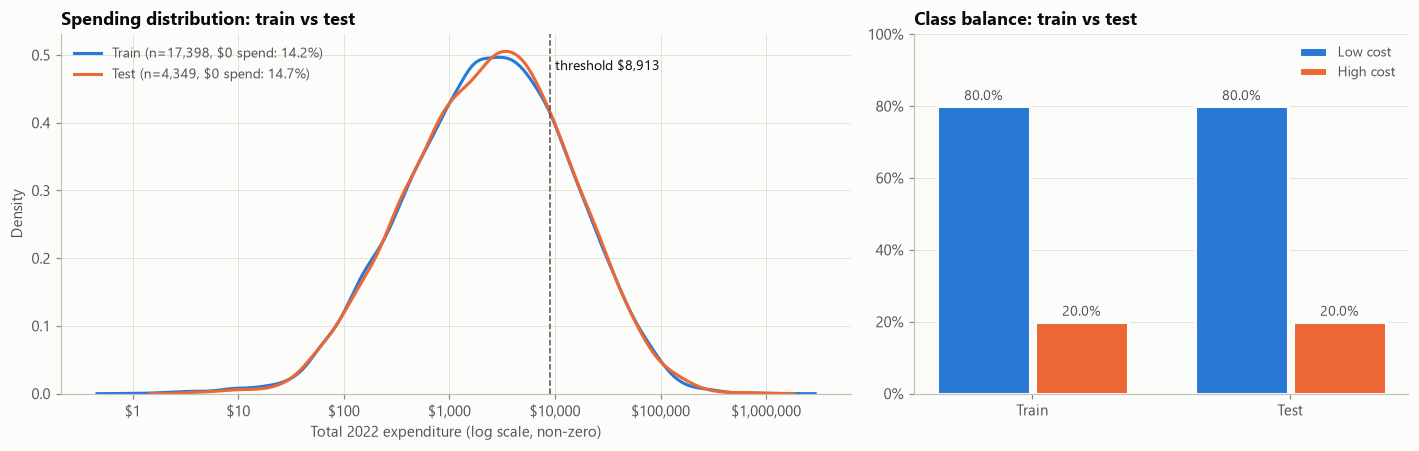

In [7]:
threshold = high_cost_threshold(train_df[TARGET_COL], THRESHOLD_QUANTILE)
y_train = make_label(train_df[TARGET_COL], threshold).reset_index(drop=True)
y_test = make_label(test_df[TARGET_COL], threshold).reset_index(drop=True)

print(f"High-cost threshold (P80 of training spending): ${threshold:,.2f}")
print(f"For reference, P80 on the full population (EDA):  ${eda['target']['p80_full_population_usd']:,.2f}")
print(f"High-cost share - train: {y_train.mean():.2%}  |  test: {y_test.mean():.2%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
for part, color, name in [(train_df, LOW_COST_COLOR, "Train"), (test_df, HIGH_COST_COLOR, "Test")]:
    spend = part.loc[part[TARGET_COL] > 0, TARGET_COL]
    sns.kdeplot(np.log10(spend), ax=axes[0], color=color, linewidth=2,
                label=f"{name} (n={len(part):,}, $0 spend: {(part[TARGET_COL] == 0).mean():.1%})")
axes[0].axvline(np.log10(threshold), color=INK_SECONDARY, linestyle="--", linewidth=1)
axes[0].text(np.log10(threshold) + 0.05, axes[0].get_ylim()[1] * 0.9, f"threshold ${threshold:,.0f}",
             fontsize=9, color=INK)
axes[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${10**x:,.0f}"))
axes[0].set_xlabel("Total 2022 expenditure (log scale, non-zero)")
axes[0].set_ylabel("Density")
axes[0].legend(loc="upper left", fontsize=9)
axes[0].set_title("Spending distribution: train vs test")

balance = pd.DataFrame({"Train": y_train.value_counts(normalize=True), "Test": y_test.value_counts(normalize=True)}) * 100
x = np.arange(2)
for i, (cls, color, label) in enumerate([(0, LOW_COST_COLOR, "Low cost"), (1, HIGH_COST_COLOR, "High cost")]):
    bars = axes[1].bar(x + (i - 0.5) * 0.38, balance.loc[cls], width=0.36, color=color, label=label,
                       edgecolor=SURFACE, linewidth=2)
    axes[1].bar_label(bars, fmt="%.1f%%", fontsize=9, color=INK_SECONDARY, padding=2)
axes[1].set_xticks(x, ["Train", "Test"])
axes[1].set_ylim(0, 100)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter())
axes[1].grid(axis="x", visible=False)
axes[1].legend(fontsize=9)
axes[1].set_title("Class balance: train vs test")
fig.tight_layout()
save_fig(fig, "03_split_check")
plt.show()

#### 📖 What this chart shows (in plain English)
**Left:** the spending curves for train (blue) and test (orange) lie almost on top of each other, and the share of $0 spenders is nearly the same (14.2% vs 14.7%). The test set is a fair sample of the same population.

**Right:** both sides have the same **80% low-cost / 20% high-cost** mix.

The threshold learned from the training data (**$8,913**) is almost identical to the full-population value from the EDA ($8,914). Computing it on training data only costs nothing here, and keeps the process clean.

## Step 6 - Separate inputs (X), target (y) and groups

**🛠️ What this code does:** Creates the standard machine-learning objects:
- **`X_train` / `X_test`:** the 41 candidate feature columns (the inputs).
- **`y_train` / `y_test`:** the `HIGH_COST` label (what we want to predict).
- **`groups_train`:** the household ID, so cross-validation can also keep households together.

In [8]:
X_train = features.iloc[train_idx].reset_index(drop=True)
X_test = features.iloc[test_idx].reset_index(drop=True)
groups_train = df[GROUP_COL].iloc[train_idx].reset_index(drop=True)

print(f"X_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}    y_test:  {y_test.shape}")
groups = feature_groups(ALL_CANDIDATES)
display(pd.DataFrame({"group": list(groups), "n_columns": [len(v) for v in groups.values()],
                      "columns": [", ".join(v) for v in groups.values()]}))

X_train: (17398, 41)   y_train: (17398,)
X_test:  (4349, 41)    y_test:  (4349,)


,group,n_columns,columns
0,numeric,7,"AGELAST, FAMSZE22, N_CONDITIONS, N_LIMITATIONS..."
1,skewed,1,POVLEV22
2,ordinal,3,"RTHLTH53, MNHLTH53, POVCAT22"
3,categorical,30,"SEX, RACETHX, REGION22, MARRY22X, HIDEG, INSCO..."


**📖 What the result shows:**
The 41 inputs fall into four preprocessing groups:
- **numeric:** counts and continuous values.
- **skewed:** `POVLEV22`, which needs a stronger transform.
- **ordinal:** ordered 1-5 scales.
- **categorical:** nominal codes and yes/no flags.

Each group gets its own treatment in the pipeline.

## Step 7 - Build the preprocessing pipeline

> **🎓 Theory in brief**
>
> A scikit-learn **`Pipeline`** chains steps so they always run in the same order. A **`ColumnTransformer`** sends each group of columns to its own pipeline.
> 
> - **Imputation** (`SimpleImputer`) fills NaN with the training median (numbers) or the most frequent value (categories).
> - **Scaling** (`StandardScaler`) rescales to mean 0 and standard deviation 1. Distance- and gradient-based models (KNN, SVM, logistic regression) need this; trees don't, but it doesn't hurt them.
> - **Power transform** (`PowerTransformer`, Yeo-Johnson) makes a long-tailed column more bell-shaped. Unlike a log, it works with negative values.
> - **One-hot encoding** (`OneHotEncoder`) turns a category column into 0/1 columns, one per category, so no false order is implied ("West = 4" is not "twice" "Midwest = 2").
> 
> Because everything sits in one object, calling `fit` on training data learns all the statistics at once, and `transform` re-uses them on new data. This makes leakage much harder.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#66-pipelines-and-the-fittransform-rule)*

**🛠️ What this code does:** Builds the `ColumnTransformer` from `src/preprocessing.py` for all 41 candidates and shows it as an interactive diagram (click a box to see its settings). The table lists which steps each column group goes through.

In [9]:
preprocessor = build_preprocessor(ALL_CANDIDATES)
steps = {"num": "median impute -> standard scale", "skew": "median impute -> Yeo-Johnson power transform",
         "ord": "median impute (+ missing flag) -> standard scale",
         "cat": "most-frequent impute -> one-hot encode (rare categories pooled)"}
display(pd.DataFrame([(name, len(cols), steps[name]) for name, _, cols in preprocessor.transformers],
                     columns=["block", "n_input_columns", "steps"]))
preprocessor

,block,n_input_columns,steps
0,num,7,median impute -> standard scale
1,skew,1,median impute -> Yeo-Johnson power transform
2,ord,3,median impute (+ missing flag) -> standard scale
3,cat,30,most-frequent impute -> one-hot encode (rare c...


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('skew', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_

**📖 What the result shows:**
The diagram is the exact recipe that will run inside every model in notebooks 04-06. Two settings are worth noting:
- **`handle_unknown="infrequent_if_exist"`:** if a category appears in new data that training never saw, it goes into an "infrequent" column instead of crashing the model.
- **`min_frequency=50`:** categories with fewer than 50 training rows (mostly refused/don't-know leftovers) are pooled into one "infrequent" column instead of getting a tiny column each.

## Step 8 - Fit on the training set, transform both sets

**🛠️ What this code does:** Runs **`fit_transform` on the training data**, which learns medians, scaling statistics and category lists and applies them. It then runs **`transform` only on the test data**, re-using what was learned from training. The output is set to a pandas DataFrame so the new column names stay readable.

In [10]:
preprocessor.set_output(transform="pandas")
Xt_train = preprocessor.fit_transform(X_train)
Xt_test = preprocessor.transform(X_test)          # transform only, never fit, on test data

print(f"Encoded training data: {Xt_train.shape[0]:,} rows x {Xt_train.shape[1]} columns")
print(f"Encoded test data:     {Xt_test.shape[0]:,} rows x {Xt_test.shape[1]} columns")
print(f"Missing values left:   train {int(Xt_train.isna().sum().sum())}, test {int(Xt_test.isna().sum().sum())}")
scaled = [c for c in Xt_train.columns if c.startswith(("num__", "skew__", "ord__")) and "missingindicator" not in c]
print(f"\nScaled columns on training data: mean ≈ {Xt_train[scaled].mean().abs().max():.3f}, "
      f"std ≈ {Xt_train[scaled].std().mean():.3f}")
display(Xt_train.iloc[:5, :10].round(2))

Encoded training data: 17,398 rows x 114 columns
Encoded test data:     4,349 rows x 114 columns
Missing values left:   train 0, test 0

Scaled columns on training data: mean ≈ 0.000, std ≈ 1.000


,num__AGELAST,num__FAMSZE22,num__N_CONDITIONS,num__N_LIMITATIONS,num__ANY_LIMITATION,num__OUT_OF_SCOPE_1231,num__AGE_BAND,skew__POVLEV22,ord__RTHLTH53,ord__MNHLTH53
0,1.39,-1.17,2.52,1.91,2.26,-0.09,1.18,-0.62,0.67,0.79
1,0.60,-1.17,-0.79,-0.37,-0.44,-0.09,0.53,-0.18,-0.30,0.79
2,-0.08,-0.58,-0.79,-0.37,-0.44,-0.09,-0.12,-0.50,-0.30,-1.20
3,-1.50,-0.58,-0.79,-0.37,-0.44,-0.09,-1.42,-0.50,-1.27,-1.20
4,1.18,-1.17,0.31,0.77,2.26,-0.09,1.18,0.78,-1.27,-1.20


**📖 What the result shows:**
- 41 input columns became **114 encoded columns**, because each category of a categorical feature becomes its own 0/1 column.
- **No missing values remain** in either set.
- Scaled columns now have **mean 0 and standard deviation 1** on the training data. On the test data they will be close to, but not exactly, 0 and 1, which is expected: the test set was transformed with the *training* statistics.

Column names show where each one came from: `num__AGELAST` is scaled age, and `cat__INSCOV22_2.0` is the 0/1 column for "public insurance only".

**🛠️ What this code does:** Visualises what the transformations did to three columns: income as % of the poverty line (`POVLEV22`, Yeo-Johnson), age (standard scaling), and insurance type (one-hot encoding).

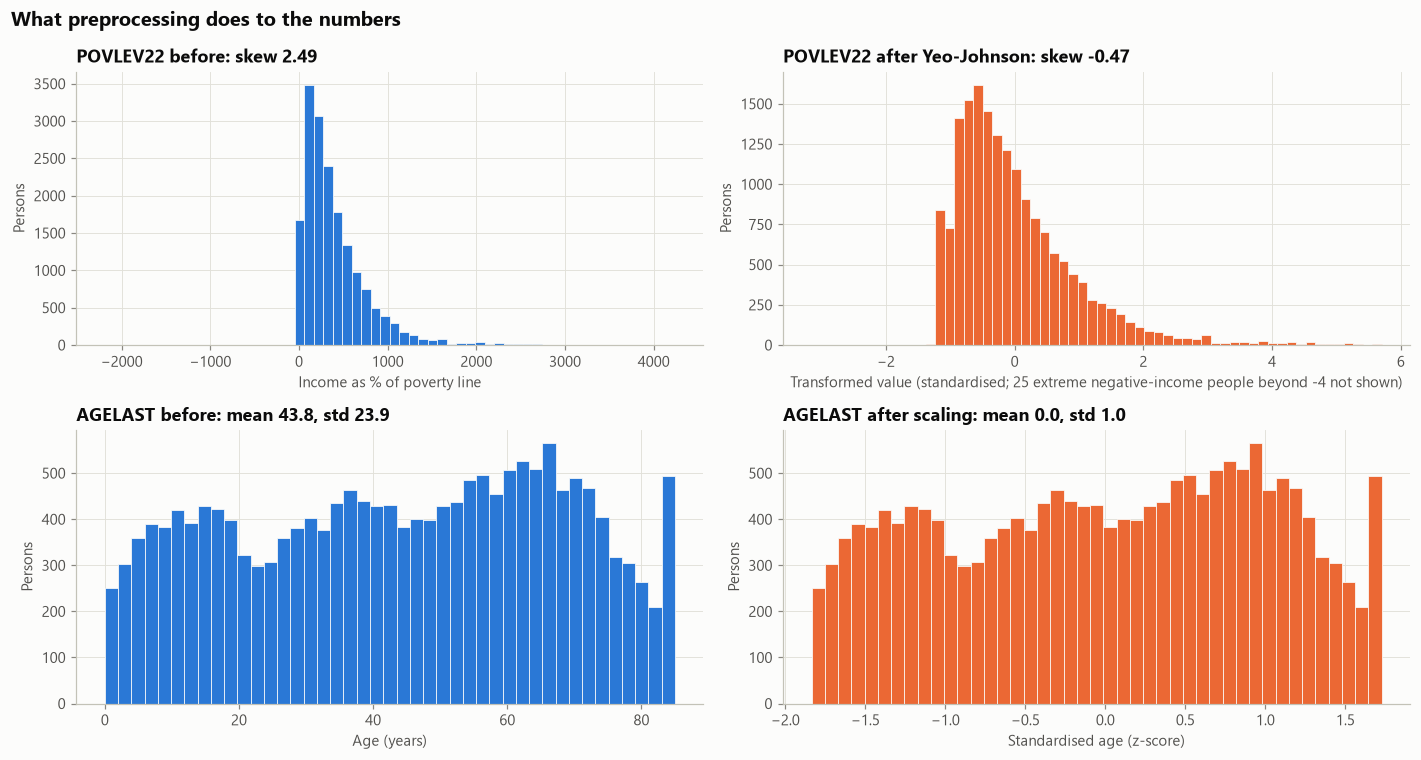

One-hot encoding of INSCOV22 (1 = any private, 2 = public only, 3 = uninsured):


,INSCOV22 (raw),cat__INSCOV22_1.0,cat__INSCOV22_2.0,cat__INSCOV22_3.0
0,2,0,1,0
1,3,0,0,1
2,1,1,0,0
3,1,1,0,0
4,1,1,0,0
5,1,1,0,0


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes[0, 0].hist(X_train["POVLEV22"], bins=60, color=LOW_COST_COLOR, edgecolor=SURFACE, linewidth=0.5)
axes[0, 0].set_title(f"POVLEV22 before: skew {X_train['POVLEV22'].skew():.2f}")
axes[0, 0].set_xlabel("Income as % of poverty line")
after = Xt_train["skew__POVLEV22"]
inside = after.between(-4, 6)
axes[0, 1].hist(after[inside], bins=60, color=HIGH_COST_COLOR, edgecolor=SURFACE, linewidth=0.5)
axes[0, 1].set_title(f"POVLEV22 after Yeo-Johnson: skew {after.skew():.2f}")
axes[0, 1].set_xlabel(f"Transformed value (standardised; {(~inside).sum()} extreme negative-income people beyond -4 not shown)")
axes[1, 0].hist(X_train["AGELAST"], bins=43, color=LOW_COST_COLOR, edgecolor=SURFACE, linewidth=0.5)
axes[1, 0].set_title(f"AGELAST before: mean {X_train['AGELAST'].mean():.1f}, std {X_train['AGELAST'].std():.1f}")
axes[1, 0].set_xlabel("Age (years)")
axes[1, 1].hist(Xt_train["num__AGELAST"], bins=43, color=HIGH_COST_COLOR, edgecolor=SURFACE, linewidth=0.5)
axes[1, 1].set_title(f"AGELAST after scaling: mean {Xt_train['num__AGELAST'].mean():.1f}, std {Xt_train['num__AGELAST'].std():.1f}")
axes[1, 1].set_xlabel("Standardised age (z-score)")
for ax in axes.ravel():
    ax.set_ylabel("Persons")
fig.suptitle("What preprocessing does to the numbers", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_transform_before_after")
plt.show()

onehot = [c for c in Xt_train.columns if c.startswith("cat__INSCOV22")]
print("One-hot encoding of INSCOV22 (1 = any private, 2 = public only, 3 = uninsured):")
display(pd.concat([X_train["INSCOV22"].rename("INSCOV22 (raw)"), Xt_train[onehot].astype(int)], axis=1).head(6))

#### 📖 What this chart shows (in plain English)
**Top row (`POVLEV22`):** before, income is piled up on the left with a long tail to the right (skew 2.49). After the Yeo-Johnson transform the bulk of people form a much more compact, bell-like shape and the skew falls to **-0.47**. This helps linear models, which work best when no single extreme value dominates. A handful of people with large *negative* family income (business losses) become extreme values far to the left. There are so few of them that they don't matter to the model, but they are hidden from the chart so the main shape stays visible.

**Bottom row (`AGELAST`):** the *shape* does not change at all. Only the axis changes, from years (mean 43.8) to "standard deviations from the average" (mean 0). Scaling puts all features on a comparable scale, so, for example, KNN does not treat 10 years of age as more important than one extra condition just because the number is bigger.

**Table:** the single `INSCOV22` column became three 0/1 columns, and each person has a 1 in exactly one of them.

## Step 9 - Feature selection

> **🎓 Theory in brief**
>
> **Feature selection** keeps the inputs that carry useful, non-duplicated information. Fewer features means faster, simpler, easier-to-explain models, and sometimes better ones. There are three families of methods:
> 
> | Family | Idea | Methods used here |
> |---|---|---|
> | **Filter** | Score each feature on its own, before any model | Spearman correlation (redundancy), ANOVA F-test, chi-square test, mutual information |
> | **Wrapper** | Try subsets of features with a model and keep the best | Recursive Feature Elimination with cross-validation (RFECV) |
> | **Embedded** | The model selects features while it trains | L1 (Lasso) logistic regression, Random Forest importance |
> 
> No single method is trusted alone. A feature is dropped only if it is **redundant**, or **weak on every method**.
> 
> *Caveat:* selection here uses the whole training set, so the cross-validation scores in later notebooks are very slightly optimistic. The **test set is untouched**, so the final evaluation stays honest.
>
> *More detail: [Theory notes](../docs/THEORY_NOTES.md#8-feature-selection)*

### 9a - Filter: remove redundant features (correlation)

**🛠️ What this code does:** Computes the **Spearman correlation** between every pair of numeric, ordinal and engineered features on the training data, draws it as a heatmap, and lists the pairs that are almost duplicates (|ρ| > 0.9).

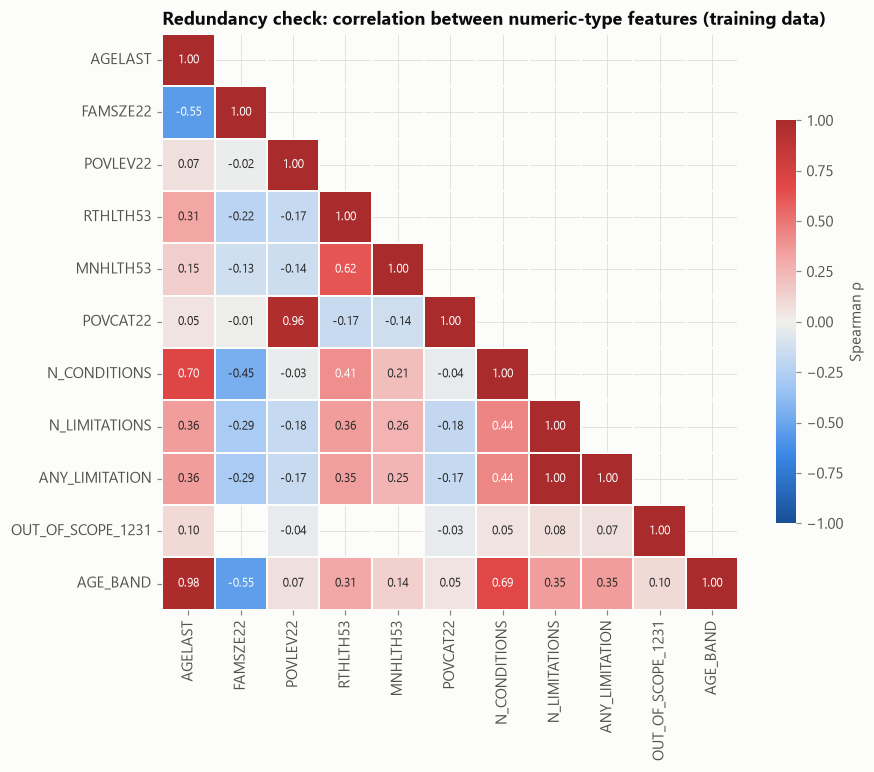

Near-duplicate pairs (|ρ| > 0.9):
N_LIMITATIONS  ANY_LIMITATION    0.995
AGELAST        AGE_BAND          0.983
POVLEV22       POVCAT22          0.960


In [12]:
num_like = NUMERIC + SKEWED_NUMERIC + ORDINAL + ENGINEERED_NUMERIC
corr = X_train[num_like].corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 7))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True,
            linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"},
            annot_kws={"fontsize": 8}, ax=ax)
ax.set_title("Redundancy check: correlation between numeric-type features (training data)")
fig.tight_layout()
save_fig(fig, "03_redundancy_heatmap")
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
redundant_pairs = pairs[pairs.abs() > 0.9].sort_values(ascending=False)
print("Near-duplicate pairs (|ρ| > 0.9):")
print(redundant_pairs.round(3).to_string())

REDUNDANT = {
    "AGE_BAND": "duplicates AGELAST (exact age keeps more detail; trees find their own cut-points)",
    "POVCAT22": "duplicates POVLEV22 (POVCAT22 is just POVLEV22 cut into 5 groups)",
    "ANY_LIMITATION": "duplicates N_LIMITATIONS (the count keeps more detail than yes/no)",
}
assert set(REDUNDANT) == {b if b in REDUNDANT else a for a, b in redundant_pairs.index}

#### 📖 What this chart shows (in plain English)
Three pairs are almost perfect duplicates:
- **`AGELAST` and `AGE_BAND` (ρ ≈ 0.98):** the age band is just age cut into groups.
- **`POVLEV22` and `POVCAT22` (ρ ≈ 0.96):** the poverty category is the poverty percentage cut into 5 groups.
- **`N_LIMITATIONS` and `ANY_LIMITATION` (ρ ≈ 0.995):** Spearman correlation compares rank order, and with most people at 0 limitations, "how many" and "any" sort people almost identically.

For each pair we keep the **more detailed** version and drop the other. Duplicates add no new information. They also confuse linear models, whose coefficients become unstable, and Naive Bayes, which assumes features are independent.

Other relationships are strong but not duplicates. For example, age and number of conditions (ρ ≈ 0.70) measure different things, so both stay.

The blank cells in the `OUT_OF_SCOPE_1231` row are not an error. Family size and the two health ratings are missing for *every* out-of-scope person, so no correlation can be computed there.

### 9b - Filter: how strongly is each feature related to the target?

**🛠️ What this code does:** Scores every feature's relationship with `HIGH_COST` using three classic statistical tests from `sklearn.feature_selection`:
- **Mutual information:** how much knowing the feature reduces uncertainty about the target. It works for any type of feature and catches non-linear patterns. This is the main ranking.
- **ANOVA F-test (`f_classif`):** do high-cost and low-cost people have different *averages*? Used for numeric and ordinal features.
- **Chi-square (`chi2`):** are categories spread differently between the two classes? Used on the one-hot columns of categorical features; each feature gets its strongest column's score.

Missing values are filled with the training median or mode first, because these tests cannot handle NaN. The two continuous columns (age, poverty level) are cut into 10 equal-size groups before mutual information is computed. Without this, family members, who all share their family's exact income value, make the estimator see a pattern that isn't there: `POVLEV22` would score 0.032 instead of 0.002.

,type,mutual_info,anova_F,anova_p,chi2,chi2_p
N_CONDITIONS,engineered,0.0790,3581.1582,0.0000,NaN,NaN
N_LIMITATIONS,engineered,0.0543,2408.1548,0.0000,NaN,NaN
ARTHDX,yes/no flag,0.0522,NaN,NaN,1291.9149,0.0000
ANY_LIMITATION,engineered,0.0507,2392.3194,0.0000,NaN,NaN
AGELAST,numeric,0.0504,1800.3957,0.0000,NaN,NaN
AGE_BAND,engineered,0.0483,1744.7731,0.0000,NaN,NaN
WLKLIM31,yes/no flag,0.0441,NaN,NaN,1661.9635,0.0000
HIBPDX,yes/no flag,0.0425,NaN,NaN,876.1627,0.0000
RTHLTH53,ordinal,0.0390,1430.9475,0.0000,NaN,NaN
CHOLDX,yes/no flag,0.0385,NaN,NaN,761.3782,0.0000


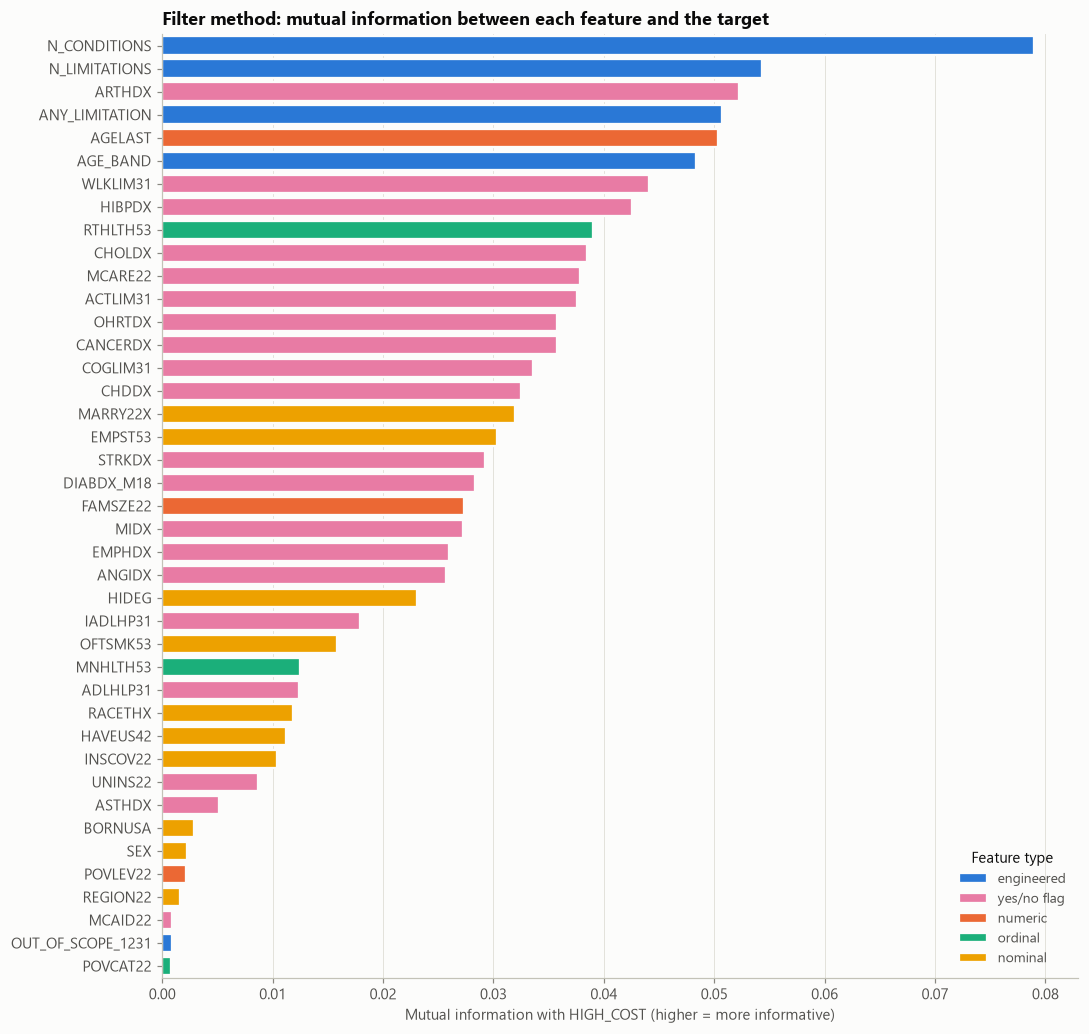

In [13]:
num_cols = NUMERIC + SKEWED_NUMERIC + ORDINAL + ENGINEERED_NUMERIC
cat_cols = NOMINAL + FLAGS
X_filled = X_train.copy()
X_filled[num_cols] = X_filled[num_cols].fillna(X_filled[num_cols].median())
X_filled[cat_cols] = X_filled[cat_cols].fillna(X_filled[cat_cols].mode().iloc[0])

def feature_type(col):
    if col in ENGINEERED_NUMERIC: return "engineered"
    if col in NUMERIC + SKEWED_NUMERIC: return "numeric"
    if col in ORDINAL: return "ordinal"
    if col in NOMINAL: return "nominal"
    return "yes/no flag"

# Continuous columns are cut into 10 equal-size groups first: the continuous MI estimator is
# distorted when many people share exactly the same value (family members share family income).
X_mi = X_filled.copy()
for c in ["AGELAST", "POVLEV22"]:
    X_mi[c] = pd.qcut(X_mi[c].rank(method="first"), 10, labels=False)
mi = pd.Series(mutual_info_classif(X_mi, y_train, discrete_features=True, random_state=RANDOM_STATE),
               index=X_mi.columns)
f_stat, f_p = f_classif(X_filled[num_cols], y_train)

def original_feature(encoded_col):
    """'cat__HIDEG_3.0' -> 'HIDEG' (longest matching candidate name)."""
    return max((c for c in ALL_CANDIDATES if c in encoded_col), key=len)

onehot_cols = [c for c in Xt_train.columns if c.startswith("cat__")]
chi_stat, chi_p = chi2(Xt_train[onehot_cols], y_train)
chi = pd.DataFrame({"feature": [original_feature(c) for c in onehot_cols], "chi2": chi_stat, "p": chi_p})
chi = chi.groupby("feature").agg(chi2=("chi2", "max"), chi2_p=("p", "min"))

filter_scores = pd.DataFrame({"type": [feature_type(c) for c in ALL_CANDIDATES],
                              "mutual_info": mi}, index=ALL_CANDIDATES)
filter_scores.loc[num_cols, "anova_F"] = f_stat
filter_scores.loc[num_cols, "anova_p"] = f_p
filter_scores = filter_scores.join(chi).sort_values("mutual_info", ascending=False)
display(filter_scores.round(4))

type_colors = dict(zip(["engineered", "numeric", "ordinal", "nominal", "yes/no flag"], SERIES[:5]))
fig, ax = plt.subplots(figsize=(10, 9.5))
sns.barplot(data=filter_scores.reset_index(names="feature"), y="feature", x="mutual_info", hue="type",
            palette=type_colors, dodge=False, saturation=1, ax=ax, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlabel("Mutual information with HIGH_COST (higher = more informative)")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)
ax.legend(title="Feature type", loc="lower right", fontsize=9)
ax.set_title("Filter method: mutual information between each feature and the target")
fig.tight_layout()
save_fig(fig, "03_filter_mutual_information")
plt.show()

#### 📖 What this chart shows (in plain English)
Each bar shows how much a feature tells us about whether a person is high-cost. Longer bars mean more useful features, and the colour shows the feature type.

- **Top:** `N_CONDITIONS` (0.079) is clearly the most informative, followed by the number of limitations, arthritis, age and the other health flags. The health block dominates, exactly as in the EDA.
- **Middle:** marital status, employment and education carry some information, mostly because they go together with age. For example, "widowed" and "not employed" are more common among older people.
- **Bottom:** `POVCAT22`, `OUT_OF_SCOPE_1231`, `MCAID22`, `REGION22`, `POVLEV22`, `SEX` and `BORNUSA` tell us almost nothing *on their own*. `OUT_OF_SCOPE_1231` scores low because it applies to only 1% of people. Mutual information measures information about *everyone*, so a rare flag scores low even if it matters a lot for those few.
- **ANOVA agrees:** `POVLEV22` has an F of only about 10, versus 3,581 for `N_CONDITIONS`. The average income of high- and low-cost people is almost the same.

A low filter score doesn't automatically make a feature useless. Filters look at one feature at a time, and a feature can still help *in combination* with others. That is why the wrapper and embedded methods follow.

The p-values in the table are almost all far below 0.05, so nearly every feature has *some* statistically significant link to the target. With 17,000 people, even tiny effects become "significant". That is why we rank features by **size of effect** (mutual information), not by p-value.

### 9c - Wrapper: Recursive Feature Elimination with cross-validation (RFECV)

**🛠️ What this code does:** **RFECV** starts with all encoded columns, fits a logistic regression, removes the 4 least useful columns (smallest coefficients), and repeats. At every size it measures the **cross-validated ROC-AUC** on 5 household-grouped folds. The chart shows how performance changes as features are removed, and RFECV picks the size with the best score.

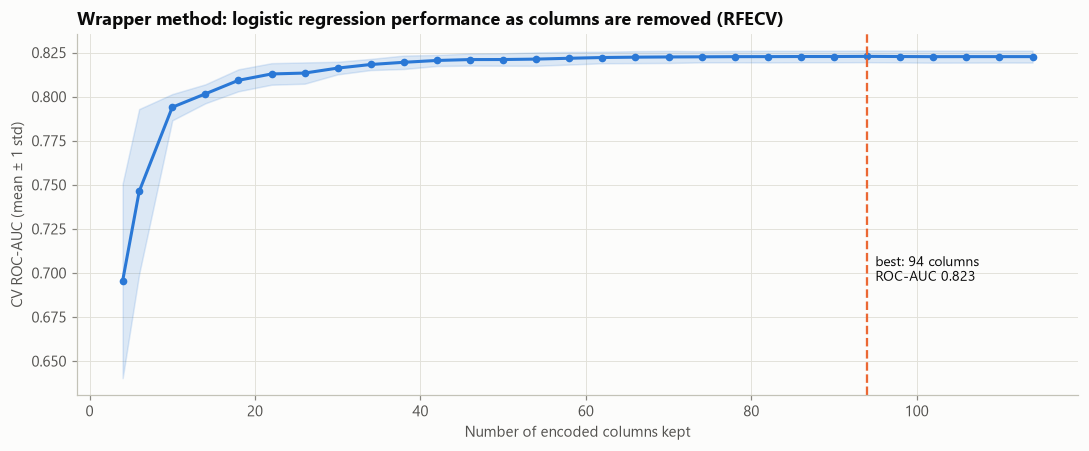

RFECV keeps 94 of 114 encoded columns, covering 39 of 41 original features.
Original features with NO column kept: ['OUT_OF_SCOPE_1231', 'POVCAT22']


In [14]:
folds = cv_folds(X_train, y_train, groups_train)
rfecv = RFECV(LogisticRegression(max_iter=5000, class_weight="balanced"), step=4, cv=folds,
              scoring="roc_auc", min_features_to_select=4, n_jobs=5)
rfecv.fit(Xt_train, y_train)

cvr = pd.DataFrame({k: v for k, v in rfecv.cv_results_.items() if np.ndim(v) == 1})
best_n = rfecv.n_features_
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(cvr["n_features"], cvr["mean_test_score"], color=LOW_COST_COLOR, marker="o", markersize=4)
ax.fill_between(cvr["n_features"], cvr["mean_test_score"] - cvr["std_test_score"],
                cvr["mean_test_score"] + cvr["std_test_score"], color=LOW_COST_COLOR, alpha=0.15)
ax.axvline(best_n, color=HIGH_COST_COLOR, linestyle="--", linewidth=1.5)
ax.text(best_n + 1, cvr["mean_test_score"].min(), f"best: {best_n} columns\nROC-AUC {cvr['mean_test_score'].max():.3f}",
        fontsize=9, color=INK)
ax.set_xlabel("Number of encoded columns kept")
ax.set_ylabel("CV ROC-AUC (mean ± 1 std)")
ax.set_title("Wrapper method: logistic regression performance as columns are removed (RFECV)")
fig.tight_layout()
save_fig(fig, "03_rfecv_curve")
plt.show()

rfe_kept = pd.Series(rfecv.support_, index=Xt_train.columns)
rfe_by_feature = rfe_kept.groupby([original_feature(c) for c in rfe_kept.index]).any()
print(f"RFECV keeps {best_n} of {Xt_train.shape[1]} encoded columns, "
      f"covering {int(rfe_by_feature.sum())} of {len(ALL_CANDIDATES)} original features.")
print("Original features with NO column kept:", sorted(rfe_by_feature[~rfe_by_feature].index))

#### 📖 What this chart shows (in plain English)
The curve shows the cross-validated ROC-AUC (y-axis) for each number of encoded columns kept (x-axis). The shaded band is the spread across the 5 folds.

- With only 4 columns the AUC is about **0.70**. It climbs quickly as columns are added and **levels off at around 40 columns** (≈ 0.820).
- The best score is **0.823 with 94 columns**. That is only a hair above the plateau: anything from about 60 to 114 columns scores the same within the fold spread.
- RFECV removed every column of `POVCAT22` and `OUT_OF_SCOPE_1231`, whose information already exists in other columns, plus 18 one-hot columns from features that keep their other columns.

**Lesson:** after the first ~40 columns, extra columns barely help a linear model, but they don't hurt it either.

### 9d - Embedded: L1 logistic regression and Random Forest importance

**🛠️ What this code does:** Two models that rank features *while they train*:
- **L1 (Lasso) logistic regression:** the L1 penalty pushes the weights of unhelpful columns to **exactly zero**. A small `C` (strong penalty) makes this selection strict.
- **Random Forest importance:** how much each feature reduces impurity (mixing of classes) across all the trees' splits, summed over each feature's one-hot columns.

Both are fitted on the encoded training data and shown side by side.

L1 logistic regression (C=0.01): 26 of 114 encoded columns kept, 23 of 41 original features


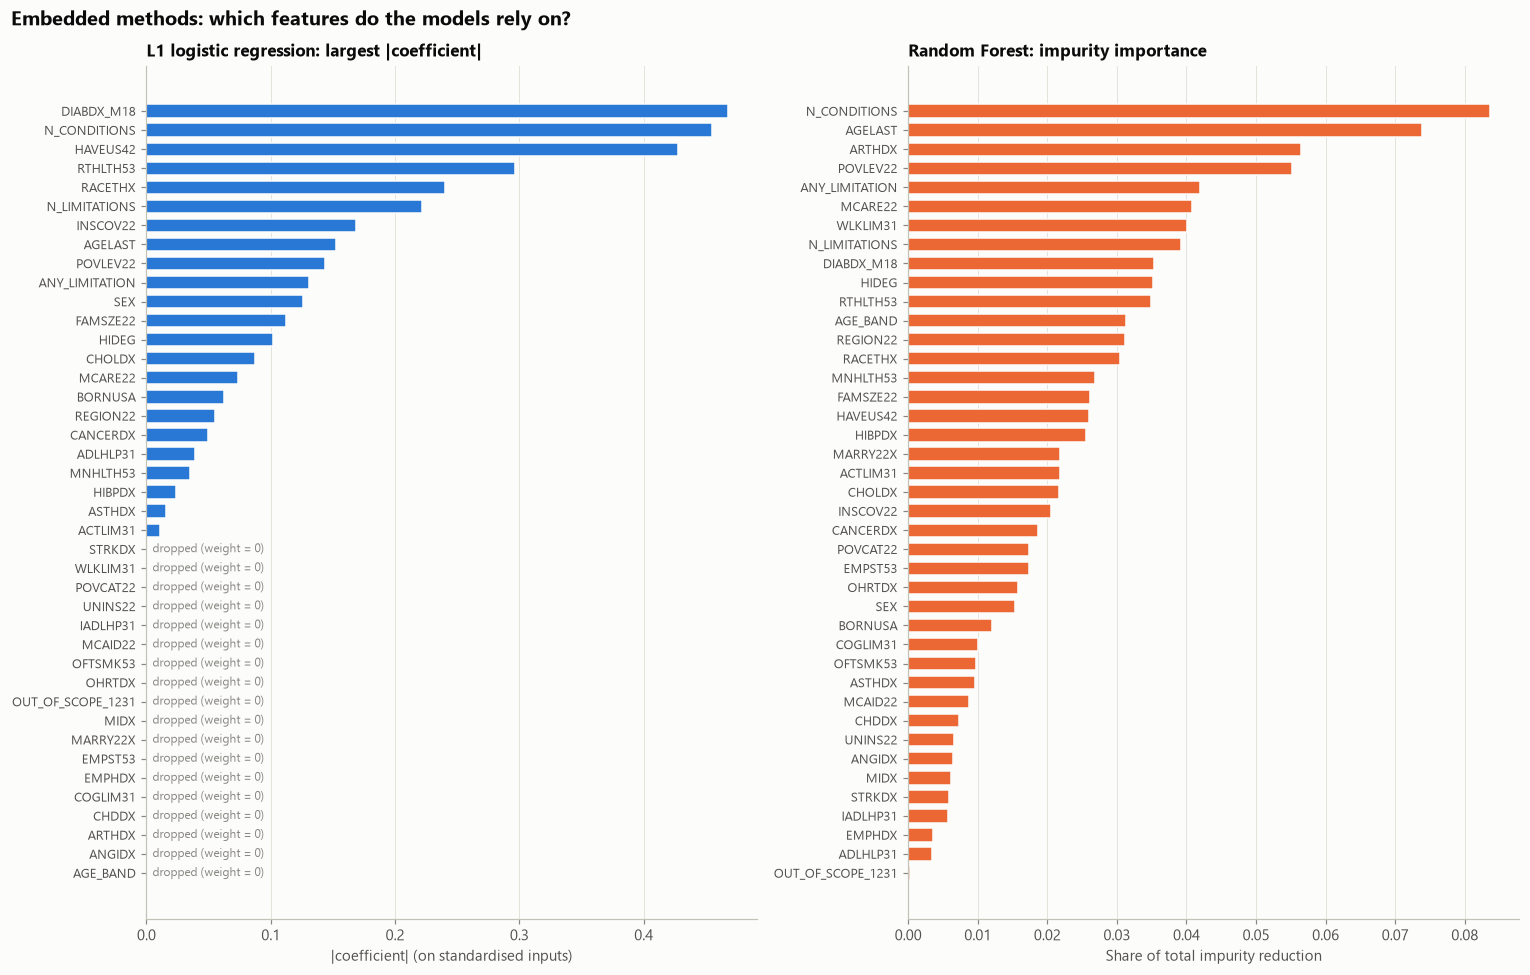

In [15]:
l1 = LogisticRegression(l1_ratio=1.0, solver="liblinear", C=0.01, class_weight="balanced", max_iter=5000)
l1.fit(Xt_train, y_train)
coef = pd.Series(np.abs(l1.coef_[0]), index=Xt_train.columns)
l1_by_feature = coef.groupby([original_feature(c) for c in coef.index]).max()
print(f"L1 logistic regression (C=0.01): {(coef > 0).sum()} of {len(coef)} encoded columns kept, "
      f"{(l1_by_feature > 0).sum()} of {len(ALL_CANDIDATES)} original features")

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xt_train, y_train)
imp = pd.Series(rf.feature_importances_, index=Xt_train.columns)
rf_by_feature = imp.groupby([original_feature(c) for c in imp.index]).sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 9))
for ax, series, title, color in [
    (axes[0], l1_by_feature.sort_values(), "L1 logistic regression: largest |coefficient|", LOW_COST_COLOR),
    (axes[1], rf_by_feature.sort_values(), "Random Forest: impurity importance", HIGH_COST_COLOR)]:
    ax.barh(series.index, series.values, color=[color if v > 0 else INK_MUTED for v in series.values],
            height=0.7, edgecolor=SURFACE, linewidth=1)
    zero = series[series == 0].index
    for name in zero:
        ax.text(0, list(series.index).index(name), "  dropped (weight = 0)", va="center", fontsize=8, color=INK_MUTED)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8.5)
    ax.set_title(title, fontsize=11)
axes[0].set_xlabel("|coefficient| (on standardised inputs)")
axes[1].set_xlabel("Share of total impurity reduction")
fig.suptitle("Embedded methods: which features do the models rely on?", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "03_embedded_importance")
plt.show()

#### 📖 What this chart shows (in plain English)
**Left (L1 logistic regression with a strong penalty, C = 0.01):** only **26 of 114 columns** keep a non-zero weight, covering 23 of the 41 features. The largest weights go to diabetes, number of conditions, having a usual source of care, physical health, race and number of limitations.

Notice that **arthritis, heart disease and stroke get weight 0**, even though they score high on mutual information. They are not useless. L1 drops them because their information is **already inside `N_CONDITIONS`**, which counts them. When features overlap, L1 tends to keep one and zero the rest. Diabetes survives, with the largest weight, because it adds risk *on top of* the count.

**Right (Random Forest):** number of conditions and age lead, as with mutual information. But `POVLEV22` ranks **4th**, although the filter tests found almost no relationship. This is a known weakness of impurity importance: a feature with many distinct values (6,653 different income values) gets many more chances to make a split, so it looks more important than it is. Permutation importance and SHAP (notebook 11) give fairer answers.

**Lesson:** every method has blind spots, which is why the final decision combines them.

### 9e - Combine the evidence and decide

**🛠️ What this code does:** Puts every method's verdict into one table and applies a simple, explicit rule:

1. **Drop** if redundant (Step 9a).
2. **Drop** if the feature is weak on **every** method: in the bottom quarter for mutual information **and** in the bottom quarter for Random Forest importance **and** removed by L1 **and** removed by RFECV.
3. Otherwise **keep**.

In [16]:
evidence = pd.DataFrame(index=ALL_CANDIDATES)
evidence["type"] = [feature_type(c) for c in ALL_CANDIDATES]
evidence["mutual_info"] = mi
evidence["rf_importance"] = rf_by_feature
evidence["l1_kept"] = l1_by_feature > 0
evidence["rfecv_kept"] = rfe_by_feature
evidence["redundant"] = evidence.index.isin(list(REDUNDANT))
evidence["weak_mi"] = evidence["mutual_info"] <= evidence["mutual_info"].quantile(0.25)
evidence["weak_rf"] = evidence["rf_importance"] <= evidence["rf_importance"].quantile(0.25)
evidence["weak_everywhere"] = (evidence.weak_mi & evidence.weak_rf & ~evidence.l1_kept & ~evidence.rfecv_kept)
evidence["decision"] = np.where(evidence.redundant, "drop (redundant)",
                                np.where(evidence.weak_everywhere, "drop (weak on all methods)", "keep"))
evidence = evidence.sort_values(["decision", "mutual_info"], ascending=[True, False])
evidence.round(4).to_csv(RESULTS / "feature_selection_evidence.csv")
display(evidence.round(4))

selected = [c for c in ALL_CANDIDATES if evidence.loc[c, "decision"] == "keep"]
dropped = {c: evidence.loc[c, "decision"] for c in ALL_CANDIDATES if c not in selected}
print(f"\nKeep {len(selected)} of {len(ALL_CANDIDATES)} candidate features. Dropped: {dropped}")

,type,mutual_info,rf_importance,l1_kept,rfecv_kept,redundant,weak_mi,weak_rf,weak_everywhere,decision
ANY_LIMITATION,engineered,0.0507,0.0420,True,True,True,False,False,False,drop (redundant)
AGE_BAND,engineered,0.0483,0.0312,False,True,True,False,False,False,drop (redundant)
POVCAT22,ordinal,0.0008,0.0174,False,False,True,True,False,False,drop (redundant)
OUT_OF_SCOPE_1231,engineered,0.0009,0.0003,False,False,False,True,True,True,drop (weak on all methods)
N_CONDITIONS,engineered,0.0790,0.0836,True,True,False,False,False,False,keep
N_LIMITATIONS,engineered,0.0543,0.0392,True,True,False,False,False,False,keep
ARTHDX,yes/no flag,0.0522,0.0564,False,True,False,False,False,False,keep
AGELAST,numeric,0.0504,0.0739,True,True,False,False,False,False,keep
WLKLIM31,yes/no flag,0.0441,0.0401,False,True,False,False,False,False,keep
HIBPDX,yes/no flag,0.0425,0.0256,True,True,False,False,False,False,keep



Keep 37 of 41 candidate features. Dropped: {'POVCAT22': 'drop (redundant)', 'ANY_LIMITATION': 'drop (redundant)', 'OUT_OF_SCOPE_1231': 'drop (weak on all methods)', 'AGE_BAND': 'drop (redundant)'}


**📖 What the result shows:**
Four features are dropped:

| Feature | Reason |
|---|---|
| `AGE_BAND` | Redundant with `AGELAST` (ρ = 0.98) |
| `POVCAT22` | Redundant with `POVLEV22` (ρ = 0.96) |
| `ANY_LIMITATION` | Redundant with `N_LIMITATIONS` (ρ = 0.995) |
| `OUT_OF_SCOPE_1231` | Weak on every method. It duplicates information already in the data: it is defined as `REGION22 = -1`, and the one-hot encoding of `REGION22` already has a column for "-1" (so do `MCARE22` and `MCAID22`). |

Three of the four dropped features are ones *we engineered*, which is a useful reminder: an engineered feature has to earn its place like any other.

Several features are weak on *some* methods but not all, for example `MCAID22`, `REGION22` and `SEX`. They stay, because at least one method (RFECV, L1 or the Random Forest) uses them. **37 features remain.**

**🛠️ What this code does:** **Checks the decision with cross-validation.** It compares the full candidate set against the selected set with two different models, logistic regression and gradient boosting, on the same 5 household-grouped folds. If the smaller set scores the same, it is the better choice: simpler, faster and easier to explain.

In [17]:
def cv_auc(columns, model):
    pipe = Pipeline([("prep", build_preprocessor(columns)), ("model", model)])
    return cross_val_score(pipe, X_train[columns], y_train, cv=folds, scoring="roc_auc", n_jobs=5)

check = []
for model_name, model in [("Logistic Regression", LogisticRegression(max_iter=5000, class_weight="balanced")),
                          ("HistGradientBoosting", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300,
                                                                                  class_weight="balanced",
                                                                                  random_state=RANDOM_STATE))]:
    for set_name, cols in [(f"all {len(ALL_CANDIDATES)} candidates", ALL_CANDIDATES),
                           (f"selected {len(selected)}", selected)]:
        s = cv_auc(cols, model)
        check.append({"model": model_name, "feature set": set_name, "CV ROC-AUC": s.mean(), "std": s.std()})
check = pd.DataFrame(check)
display(check.round(4))

,model,feature set,CV ROC-AUC,std
0,Logistic Regression,all 41 candidates,0.8228,0.0034
1,Logistic Regression,selected 37,0.8222,0.0033
2,HistGradientBoosting,all 41 candidates,0.8213,0.0043
3,HistGradientBoosting,selected 37,0.8214,0.0043


**📖 What the result shows:**
| Model | All 41 features | Selected 37 |
|---|---|---|
| Logistic Regression | 0.8228 | 0.8222 |
| HistGradientBoosting | 0.8213 | 0.8214 |

The differences (at most 0.0006) are far smaller than the fold-to-fold spread (std ≈ 0.003-0.004). Removing the four features **costs nothing**, so we keep the simpler set.

Also notice that logistic regression and gradient boosting score almost the same (≈ 0.82). That is a first hint for the model comparison in notebook 06.

## Step 10 - Save the prepared data

**🛠️ What this code does:** Saves everything the modelling notebooks need:
- **`data/processed/train.parquet` and `test.parquet`:** the cleaned candidate features plus `TOTEXP22`, `HIGH_COST`, the household ID and the person ID. The same split will be reused for the regression task later.
- **`reports/results/selected_features.json`:** the final feature list, the dropped features with reasons, the threshold and the split sizes.

The preprocessing pipeline itself is not saved. It is rebuilt and re-fitted inside every model in notebooks 04-06, which is what keeps cross-validation honest.

In [18]:
def with_labels(X, part, y):
    return X.assign(**{TARGET_COL: part[TARGET_COL].to_numpy(), LABEL_COL: y.to_numpy(),
                       GROUP_COL: part[GROUP_COL].to_numpy(), ID_COL: part[ID_COL].to_numpy()})

train_out, test_out = with_labels(X_train, train_df, y_train), with_labels(X_test, test_df, y_test)
save_split(train_out, test_out)

SELECTED_FEATURES_PATH.write_text(json.dumps({
    "selected_features": selected,
    "dropped_features": dropped,
    "engineered_features": ENGINEERED,
    "threshold_usd": round(threshold, 2),
    "threshold_rule": f"HIGH_COST = TOTEXP22 >= P{int(THRESHOLD_QUANTILE * 100)} of the training split",
    "n_train": len(train_out), "n_test": len(test_out),
    "split": "StratifiedGroupKFold(5), groups = DUID (household), strata = spending deciles",
    "random_state": RANDOM_STATE,
}, indent=2))
print(f"Saved train ({train_out.shape}) and test ({test_out.shape}) to data/processed/")
print(f"Saved {len(selected)} selected features to {SELECTED_FEATURES_PATH.relative_to(ROOT)}")

Saved train ((17398, 45)) and test ((4349, 45)) to data/processed/
Saved 37 selected features to reports\results\selected_features.json


**📖 What the result shows:**
The files are written. Notebooks 04, 05 and 06 only ever load **`train.parquet`**. `test.parquet` stays unopened until the final evaluation in notebook 07.

## Summary

| Step | Result |
|---|---|
| Population | 21,747 persons in 10,656 households |
| Engineered features | `N_CONDITIONS`, `N_LIMITATIONS` kept. `ANY_LIMITATION`, `AGE_BAND`, `OUT_OF_SCOPE_1231` created but dropped as redundant |
| Reserved codes | `-1` kept as its own category (nominal and yes/no). `-7/-8/-15` become NaN and are imputed inside the pipeline. Ordinal `-1` becomes NaN plus a missing flag |
| Split | 80/20, grouped by household, stratified by spending decile: **17,398 train / 4,349 test**, 0 shared households |
| Target | `HIGH_COST = TOTEXP22 >= $8,913` (P80 of training data). 20% positive in both sets |
| Pipeline | Median/mode imputation, standard scaling, Yeo-Johnson, one-hot encoding. Fitted on training data only |
| Feature selection | Filter + wrapper + embedded evidence leaves **37 features**. CV ROC-AUC unchanged (0.822 logistic regression, 0.821 gradient boosting) |
| Saved | `data/processed/train.parquet`, `test.parquet`, `reports/results/selected_features.json`, `feature_selection_evidence.csv` |

**Next:** `04_classification_baseline.ipynb` sets a baseline and explains every evaluation metric with charts.